In [ ]:
#Descarga del zip
import os
import zipfile

!pip install -q gdown
FILE_ID = "1prJa74vehpbJSLQ3oNLZjoL1aKaglXTf"

url = f"https://drive.google.com/uc?id={FILE_ID}"
output_zip = "dataset.zip"

print("[1/2] Descargando dataset...")
!gdown {url} -O {output_zip}

print("[2/2] Descomprimiendo archivos...")
with zipfile.ZipFile(output_zip, 'r') as zip_ref:
    zip_ref.extractall('/content')

# Detección automática de la ruta por si el zip contiene carpeta raíz o no
if os.path.exists('/content/dataset'):
    DATASET_DIR = '/content/dataset'
else:
    DATASET_DIR = '/content'

print(f"Dataset listo en: {DATASET_DIR}")

[1/2] Descargando dataset...
Downloading...
From: https://drive.google.com/uc?id=1prJa74vehpbJSLQ3oNLZjoL1aKaglXTf
To: /content/dataset.zip
100% 4.02M/4.02M [00:00<00:00, 185MB/s]
[2/2] Descomprimiendo archivos...
Dataset listo en: /content/dataset


**DATA AUMENTATION**

In [ ]:
import os
import glob
import random
import numpy as np
import cv2
from scipy.ndimage import map_coordinates, gaussian_filter

# Función para deformación elástica (simula el pulso y temblor humano)
def elastic_transform(image, alpha=36, sigma=4, random_state=None):
    if random_state is None:
        random_state = np.random.RandomState(None)
    shape = image.shape
    dx = gaussian_filter((random_state.rand(*shape) * 2 - 1), sigma, mode="constant", cval=0) * alpha
    dy = gaussian_filter((random_state.rand(*shape) * 2 - 1), sigma, mode="constant", cval=0) * alpha
    x, y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    indices = np.reshape(y + dy, (-1, 1)), np.reshape(x + dx, (-1, 1))
    return map_coordinates(image, indices, order=1, mode='reflect').reshape(shape)

# Transformaciones morfológicas y geométricas con OpenCV
def augment_unown(img_gray):
    h, w = img_gray.shape

    # 1. Rotación aleatoria (-20 a +20 grados)
    angle = random.uniform(-20, 20)
    center = (w // 2, h // 2)
    rot_mat = cv2.getRotationMatrix2D(center, angle, 1.0)
    augmented = cv2.warpAffine(img_gray, rot_mat, (w, h), borderValue=0)

    # 2. Escalado / Zoom aleatorio leve (0.85 a 1.15)
    scale = random.uniform(0.85, 1.15)
    scale_mat = cv2.getRotationMatrix2D(center, 0, scale)
    augmented = cv2.warpAffine(augmented, scale_mat, (w, h), borderValue=0)

    # 3. Traslación aleatoria (-5 a +5 px)
    tx, ty = random.uniform(-5, 5), random.uniform(-5, 5)
    trans_mat = np.float32([[1, 0, tx], [0, 1, ty]])
    augmented = cv2.warpAffine(augmented, trans_mat, (w, h), borderValue=0)

    # 4. Variación de grosor de trazo (Erosión / Dilatación morfológica)
    kernel_size = random.choice([1, 2, 3])
    kernel = np.ones((kernel_size, kernel_size), np.uint8)
    if random.random() > 0.5:
        augmented = cv2.dilate(augmented, kernel, iterations=1)
    else:
        augmented = cv2.erode(augmented, kernel, iterations=1)

    # 5. Deformación elástica de pulso
    if random.random() > 0.3:
        augmented = elastic_transform(augmented, alpha=random.uniform(20, 35), sigma=random.uniform(3, 5))

    # 6. Ruido gaussiano leve
    noise = np.random.normal(0, random.uniform(2, 8), (h, w)).astype(np.float32)
    augmented = np.clip(augmented.astype(np.float32) + noise, 0, 255).astype(np.uint8)

    return cv2.resize(augmented, (64, 64), interpolation=cv2.INTER_AREA)

# Generar ~500 muestras por cada una de las 5 letras
OUTPUT_DATASET_DIR = "/content/dataset_sintetico"
SAMPLES_PER_CLASS = 520  # ~2600 imágenes en total

print("Generando dataset sintético con OpenCV...")
for cls in ['A', 'B', 'C', 'D', 'E']:
    cls_out_dir = os.path.join(OUTPUT_DATASET_DIR, cls)
    os.makedirs(cls_out_dir, exist_ok=True)

    # Busca la imagen plantilla original de esa letra (por ejemplo en /content/templates/A.png)
    template_candidates = glob.glob(f"{DATASET_DIR}/{cls}/*.png") + glob.glob(f"{DATASET_DIR}/{cls}/*.jpg")
    if not template_candidates:
        continue
    ruta_elegida = random.choice(template_candidates)
    base_img = cv2.imread(ruta_elegida, cv2.IMREAD_GRAYSCALE)
    if np.mean(base_img) > 127:  # Asegurar fondo negro y trazo blanco
        base_img = 255 - base_img

    for i in range(SAMPLES_PER_CLASS):
        aug_img = augment_unown(base_img)
        save_path = os.path.join(cls_out_dir, f"{cls}_syn_{i:04d}.png")
        cv2.imwrite(save_path, aug_img)

print(f"¡Dataset sintético creado con éxito en: {OUTPUT_DATASET_DIR}!")

**Carga de datos y partición estricta 80/20 (Entrenamiento y Prueba)**

In [ ]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Normalización idéntica al modelo original: 64x64, escala de grises y tensores [0, 1]
data_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

full_dataset = datasets.ImageFolder(root=DATASET_DIR, transform=data_transforms)
clases = full_dataset.classes
print(f"Clases detectadas ({len(clases)}): {clases}")

# Partición 80% Train y 20% Test con semilla fija para reproducibilidad matemática
total_muestras = len(full_dataset)
train_size = int(0.80 * total_muestras)
test_size = total_muestras - train_size

train_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print(f"Total de imágenes: {total_muestras}")
print(f"-> Muestras de Entrenamiento (80%): {len(train_dataset)}")
print(f"-> Muestras de Prueba (20%): {len(test_dataset)}")

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Clases detectadas (5): ['A', 'B', 'C', 'D', 'E']
Total de imágenes: 2598
-> Muestras de Entrenamiento (80%): 2078
-> Muestras de Prueba (20%): 520


**Definición de la arquitectura CNN**

In [ ]:
import torch.nn as nn

class UnownCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.35),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UnownCNN(num_classes=len(clases)).to(device)
print(f"Modelo instanciado en: {device}")

Modelo instanciado en: cpu


**Entrenamiento (10 Épocas) y Gráficas de Aprendizaje**

Época [01/10] -> Train Loss: 1.1168 | Test Loss: 0.6398 | Train Acc: 52.65% | Test Acc: 73.46%
Época [02/10] -> Train Loss: 0.5955 | Test Loss: 0.5816 | Train Acc: 74.54% | Test Acc: 74.81%
Época [03/10] -> Train Loss: 0.4851 | Test Loss: 0.6263 | Train Acc: 78.49% | Test Acc: 74.62%
Época [04/10] -> Train Loss: 0.4271 | Test Loss: 0.5490 | Train Acc: 81.09% | Test Acc: 75.96%
Época [05/10] -> Train Loss: 0.3968 | Test Loss: 0.5242 | Train Acc: 81.52% | Test Acc: 76.73%
Época [06/10] -> Train Loss: 0.3973 | Test Loss: 0.4450 | Train Acc: 81.09% | Test Acc: 80.19%
Época [07/10] -> Train Loss: 0.3587 | Test Loss: 0.9645 | Train Acc: 82.87% | Test Acc: 68.27%
Época [08/10] -> Train Loss: 0.3472 | Test Loss: 0.4809 | Train Acc: 84.02% | Test Acc: 80.58%
Época [09/10] -> Train Loss: 0.3439 | Test Loss: 0.4845 | Train Acc: 83.45% | Test Acc: 78.46%
Época [10/10] -> Train Loss: 0.3420 | Test Loss: 0.4761 | Train Acc: 83.11% | Test Acc: 81.15%
Pesos exportados en 'unown_model.pth'.


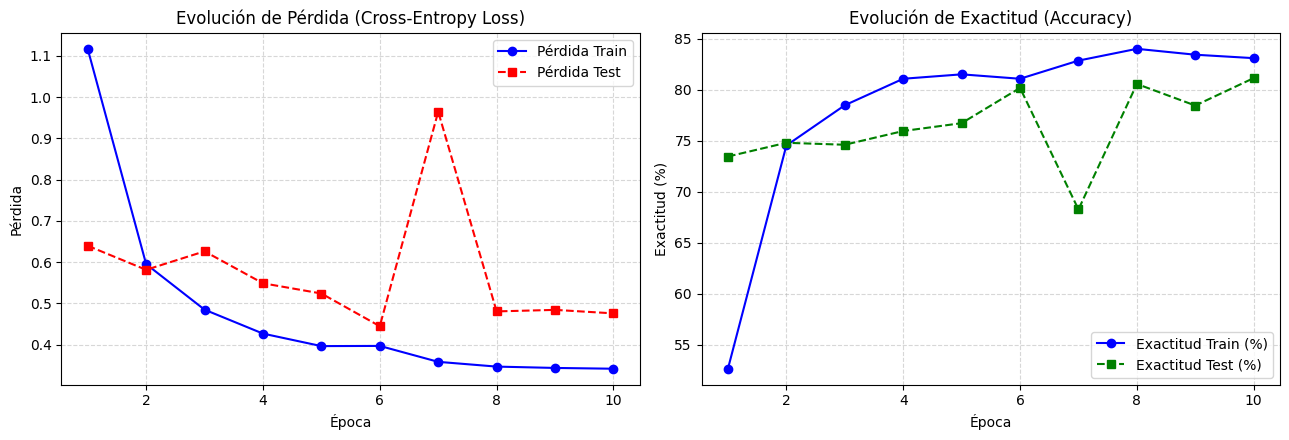

In [ ]:
import torch.optim as optim
import matplotlib.pyplot as plt

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

epochs = 10
history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

for epoch in range(1, epochs + 1):
    # --- Fase de Entrenamiento ---
    model.train()
    running_loss, correct_train = 0.0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data).item()

    train_loss = running_loss / len(train_dataset)
    train_acc = (correct_train / len(train_dataset)) * 100

    # --- Fase de Validación con el 20% de Test ---
    model.eval()
    val_loss, correct_test = 0.0, 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct_test += torch.sum(preds == labels.data).item()

    test_loss = val_loss / len(test_dataset)
    test_acc = (correct_test / len(test_dataset)) * 100

    scheduler.step(test_acc)

    history['train_loss'].append(train_loss)
    history['test_loss'].append(test_loss)
    history['train_acc'].append(train_acc)
    history['test_acc'].append(test_acc)

    print(f"Época [{epoch:02d}/{epochs:02d}] -> Train Loss: {train_loss:.4f} | Test Loss: {test_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

# Guardar los pesos para persistencia
torch.save({'model_state_dict': model.state_dict(), 'class_names': clases}, 'unown_model.pth')
print("Pesos exportados en 'unown_model.pth'.")

# Visualizar curvas
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(range(1, epochs + 1), history['train_loss'], 'bo-', label='Pérdida Train')
axs[0].plot(range(1, epochs + 1), history['test_loss'], 'rs--', label='Pérdida Test')
axs[0].set_title('Evolución de Pérdida (Cross-Entropy Loss)')
axs[0].set_xlabel('Época')
axs[0].set_ylabel('Pérdida')
axs[0].grid(True, linestyle='--', alpha=0.5)
axs[0].legend()

axs[1].plot(range(1, epochs + 1), history['train_acc'], 'bo-', label='Exactitud Train (%)')
axs[1].plot(range(1, epochs + 1), history['test_acc'], 'gs--', label='Exactitud Test (%)')
axs[1].set_title('Evolución de Exactitud (Accuracy)')
axs[1].set_xlabel('Época')
axs[1].set_ylabel('Exactitud (%)')
axs[1].grid(True, linestyle='--', alpha=0.5)
axs[1].legend()
plt.tight_layout()
plt.show()

**Matriz de Confusión y Métricas Detalladas (Accuracy Global y Top-3)**

=== REPORTE FINAL DE EVALUACIÓN (TEST SET 20%) ===
Exactitud Global (Top-1 Accuracy): 81.15%
Exactitud Top-3 (Top-3 Accuracy):  91.73%

              precision    recall  f1-score   support

           A       0.92      0.74      0.82       112
           B       1.00      0.75      0.86       107
           C       0.59      0.97      0.73       120
           D       0.96      0.78      0.86        94
           E       0.92      0.79      0.85        87

    accuracy                           0.81       520
   macro avg       0.88      0.81      0.82       520
weighted avg       0.87      0.81      0.82       520



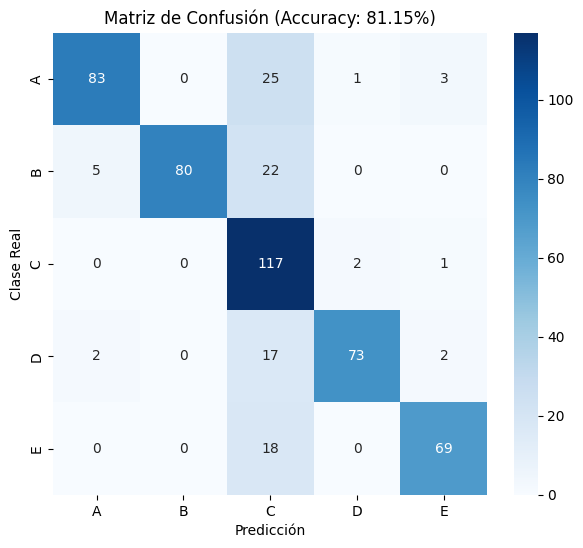

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

model.eval()
all_preds, all_labels = [], []
top3_correct, total_test_samples = 0, 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1).cpu().numpy()

        preds = np.argmax(probs, axis=1)
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

        for i, target in enumerate(labels.numpy()):
            top3 = np.argsort(probs[i])[::-1][:3]
            if target in top3:
                top3_correct += 1
            total_test_samples += 1

global_accuracy = (np.array(all_preds) == np.array(all_labels)).mean() * 100
top3_accuracy = (top3_correct / total_test_samples) * 100

print(f"=== REPORTE FINAL DE EVALUACIÓN (TEST SET 20%) ===")
print(f"Exactitud Global (Top-1 Accuracy): {global_accuracy:.2f}%")
print(f"Exactitud Top-3 (Top-3 Accuracy):  {top3_accuracy:.2f}%\n")
print(classification_report(all_labels, all_preds, target_names=clases))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clases, yticklabels=clases)
plt.title(f'Matriz de Confusión (Accuracy: {global_accuracy:.2f}%)')
plt.xlabel('Predicción')
plt.ylabel('Clase Real')
plt.show()

**Lienzo Interactivo para Dibujo en Vivo e Inferencia**


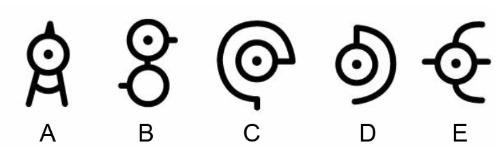

Dibuja tu símbolo fijándote en la referencia y haz clic en 'Clasificar'...


AttributeError: 'NoneType' object has no attribute 'split'

In [33]:
import base64
import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from google.colab.output import eval_js

IMG_REF_PATH = "dataset/referencia.png"  # Ajusta la ruta o nombre según corresponda

# Leer la imagen local y convertirla a Data URL Base64 para el navegador
if os.path.exists(IMG_REF_PATH):
    with open(IMG_REF_PATH, "rb") as f:
        encoded_img = base64.b64encode(f.read()).decode("utf-8")
    ref_src = f"data:image/png;base64,{encoded_img}"
else:
    # Si no encuentra el archivo, avisa en lugar de romper el código
    ref_src = ""
    print(f"Aviso: No se encontró '{IMG_REF_PATH}' en el disco. Sube el archivo al panel lateral.")

# 2. ESTRUCTURA HTML CON LA IMAGEN INYECTADA
canvas_html = f"""
<div style="font-family: system-ui, -apple-system, sans-serif; background: #0f172a; padding: 20px; border-radius: 12px; color: #f8fafc; max-width: 580px; margin: auto; box-shadow: 0 10px 25px -5px rgba(0,0,0,0.5);">
  <h3 style="margin: 0 0 12px 0; text-align: center; color: #38bdf8; letter-spacing: 0.5px;">Panel de Prueba Unown</h3>

  <!-- GUÍA DE REFERENCIA OFICIAL CARGADA DESDE ARCHIVO -->
  <div style="background: #ffffff; padding: 8px 12px; border-radius: 8px; margin-bottom: 16px; text-align: center;">
    <div style="font-size: 11px; font-weight: 700; color: #475569; margin-bottom: 4px; text-transform: uppercase;">Guía de trazo oficial</div>
    <img src="{ref_src}" style="max-width: 100%; height: auto; max-height: 120px; display: block; margin: auto; border-radius: 4px;" alt="Referencia no encontrada">
  </div>

  <!-- LIENZO DE TRAZO -->
  <div style="text-align: center;">
    <div style="font-size: 12px; margin-bottom: 8px; color: #94a3b8; font-weight: 600;">DIBUJA AQUÍ TU SÍMBOLO</div>
    <canvas id="colabCanvas" width="220" height="220" style="border: 2px solid #38bdf8; border-radius: 8px; background: #ffffff; cursor: crosshair; touch-action: none; margin: auto; display: block;"></canvas>

    <div style="margin-top: 12px; display: flex; gap: 10px; justify-content: center;">
      <button id="clearBtn" style="padding: 7px 16px; background: #ef4444; color: white; border: none; border-radius: 6px; cursor: pointer; font-weight: 600; font-size: 13px;">Borrar</button>
      <button id="predictBtn" style="padding: 7px 20px; background: #0ea5e9; color: white; border: none; border-radius: 6px; cursor: pointer; font-weight: 600; font-size: 13px;">Clasificar</button>
    </div>
  </div>
</div>

<script>
  var canvas = document.getElementById('colabCanvas');
  var ctx = canvas.getContext('2d');
  var drawing = false;
  var lastX, lastY;

  function initCanvas() {{
    ctx.fillStyle = '#ffffff';
    ctx.fillRect(0, 0, canvas.width, canvas.height);
  }}
  initCanvas();

  canvas.addEventListener('mousedown', function(e) {{
    drawing = true;
    var rect = canvas.getBoundingClientRect();
    lastX = e.clientX - rect.left;
    lastY = e.clientY - rect.top;
  }});

  canvas.addEventListener('mousemove', function(e) {{
    if (!drawing) return;
    var rect = canvas.getBoundingClientRect();
    var x = e.clientX - rect.left;
    var y = e.clientY - rect.top;
    drawStroke(lastX, lastY, x, y);
    lastX = x;
    lastY = y;
  }});

  window.addEventListener('mouseup', function() {{ drawing = false; }});

  canvas.addEventListener('touchstart', function(e) {{
    e.preventDefault();
    drawing = true;
    var rect = canvas.getBoundingClientRect();
    lastX = e.touches[0].clientX - rect.left;
    lastY = e.touches[0].clientY - rect.top;
  }});

  canvas.addEventListener('touchmove', function(e) {{
    e.preventDefault();
    if (!drawing) return;
    var rect = canvas.getBoundingClientRect();
    var x = e.touches[0].clientX - rect.left;
    var y = e.touches[0].clientY - rect.top;
    drawStroke(lastX, lastY, x, y);
    lastX = x;
    lastY = y;
  }});

  window.addEventListener('touchend', function() {{ drawing = false; }});

  function drawStroke(x1, y1, x2, y2) {{
    ctx.beginPath();
    ctx.strokeStyle = '#000000';
    ctx.lineWidth = 14;
    ctx.lineCap = 'round';
    ctx.lineJoin = 'round';
    ctx.moveTo(x1, y1);
    ctx.lineTo(x2, y2);
    ctx.stroke();
  }}

  document.getElementById('clearBtn').addEventListener('click', function() {{
    initCanvas();
  }});

  function getDrawing() {{
    return new Promise((resolve) => {{
      document.getElementById('predictBtn').onclick = () => {{
        resolve(canvas.toDataURL('image/png'));
      }};
    }});
  }}
</script>
"""

# 3. FUNCIÓN DE INFERENCIA
def clasificar_canvas():
    display(HTML(canvas_html))
    print("Dibuja tu símbolo fijándote en la referencia y haz clic en 'Clasificar'...")
    data_url = eval_js("getDrawing()")

    img_bytes = base64.b64decode(data_url.split(',')[1])
    np_arr = np.frombuffer(img_bytes, np.uint8)
    img_bgr = cv2.imdecode(np_arr, cv2.IMREAD_COLOR)

    if img_bgr is None:
        print("No se detectó ningún trazo.")
        return

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    if np.mean(gray) > 127:
        gray = 255 - gray

    processed = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA)
    tensor = torch.tensor(processed, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0
    tensor = tensor.to(device)

    model.eval()
    with torch.no_grad():
        logits = model(tensor)
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]

    top3_idx = np.argsort(probs)[::-1][:3]

    fig, ax = plt.subplots(1, 2, figsize=(8, 3))
    ax[0].imshow(processed, cmap="gray")
    ax[0].set_title("Entrada procesada (64x64)")
    ax[0].axis("off")

    clases_top3 = [clases[i] for i in top3_idx]
    probs_top3 = [probs[i] * 100 for i in top3_idx]

    bar_colors = ['#38bdf8', '#7dd3fc', '#cbd5e1']
    ax[1].barh(clases_top3[::-1], probs_top3[::-1], color=bar_colors[::-1])
    ax[1].set_xlim(0, 100)
    ax[1].set_xlabel("Confianza (%)")
    ax[1].set_title(f"Predicción: '{clases_top3[0]}'")
    for i, v in enumerate(probs_top3[::-1]):
        ax[1].text(v + 2, i, f"{v:.1f}%", va='center', fontweight='bold')

    plt.tight_layout()
    plt.show()

clasificar_canvas()